Load the data

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.datasets import fetch_openml

# Resolve project root regardless of where the kernel was started
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "configs").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "configs").is_dir():
    PROJECT_ROOT = Path("/Users/andreapenacastro/Downloads/albert school/"
                        "Applied ML - Foundations, Engineering & Evaluation/"
                        "Final Project/diabetes-readmission-ml")
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Saving figures to:", FIG_DIR)

diabetes = fetch_openml(data_id=4541, as_frame=True)
X, y = diabetes.data, diabetes.target
df = X.copy()
df["target"] = y

print(df.shape)
df.head()

Saving figures to: /Users/andreapenacastro/Downloads/albert school/Applied ML - Foundations, Engineering & Evaluation/Final Project/diabetes-readmission-ml/reports/figures
(101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide.metformin,glipizide.metformin,glimepiride.pioglitazone,metformin.rosiglitazone,metformin.pioglitazone,change,diabetesMed,target
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype   
---  ------                    --------------   -----   
 0   encounter_id              101766 non-null  int64   
 1   patient_nbr               101766 non-null  int64   
 2   race                      101766 non-null  category
 3   gender                    101766 non-null  category
 4   age                       101766 non-null  category
 5   weight                    101766 non-null  category
 6   admission_type_id         101766 non-null  int64   
 7   discharge_disposition_id  101766 non-null  int64   
 8   admission_source_id       101766 non-null  int64   
 9   time_in_hospital          101766 non-null  int64   
 10  payer_code                101766 non-null  category
 11  medical_specialty         101766 non-null  category
 12  num_lab_procedures        101766 non-null  int64   
 13  num_procedures            101

In [17]:
print(y.value_counts())
print(y.value_counts(normalize=True).round(3))

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64
readmitted
NO     0.539
>30    0.349
<30    0.112
Name: proportion, dtype: float64


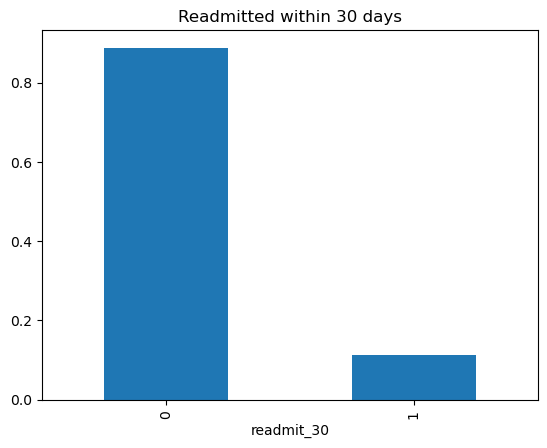

In [18]:
df["readmit_30"] = (df["target"] == "<30").astype(int)
df["readmit_30"].value_counts(normalize=True).plot(kind="bar", title="Readmitted within 30 days")
plt.savefig(FIG_DIR / "target_distribution.png", bbox_inches="tight")
plt.show()

weight               0.969
medical_specialty    0.491
payer_code           0.396
race                 0.022
diag_3               0.014
diag_2               0.004
diag_1               0.000
dtype: float64


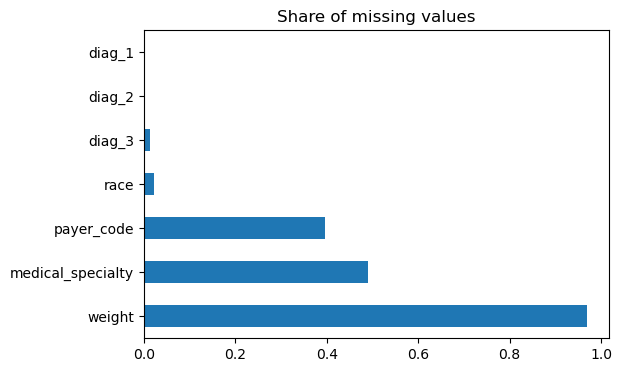

In [19]:
missing = (df.isna() | (df == "?")).mean().sort_values(ascending=False)
missing = missing[missing > 0]
print(missing.round(3))
missing.plot(kind="barh", figsize=(6, 4), title="Share of missing values")
plt.savefig(FIG_DIR / "missing_values.png", bbox_inches="tight")
plt.show()

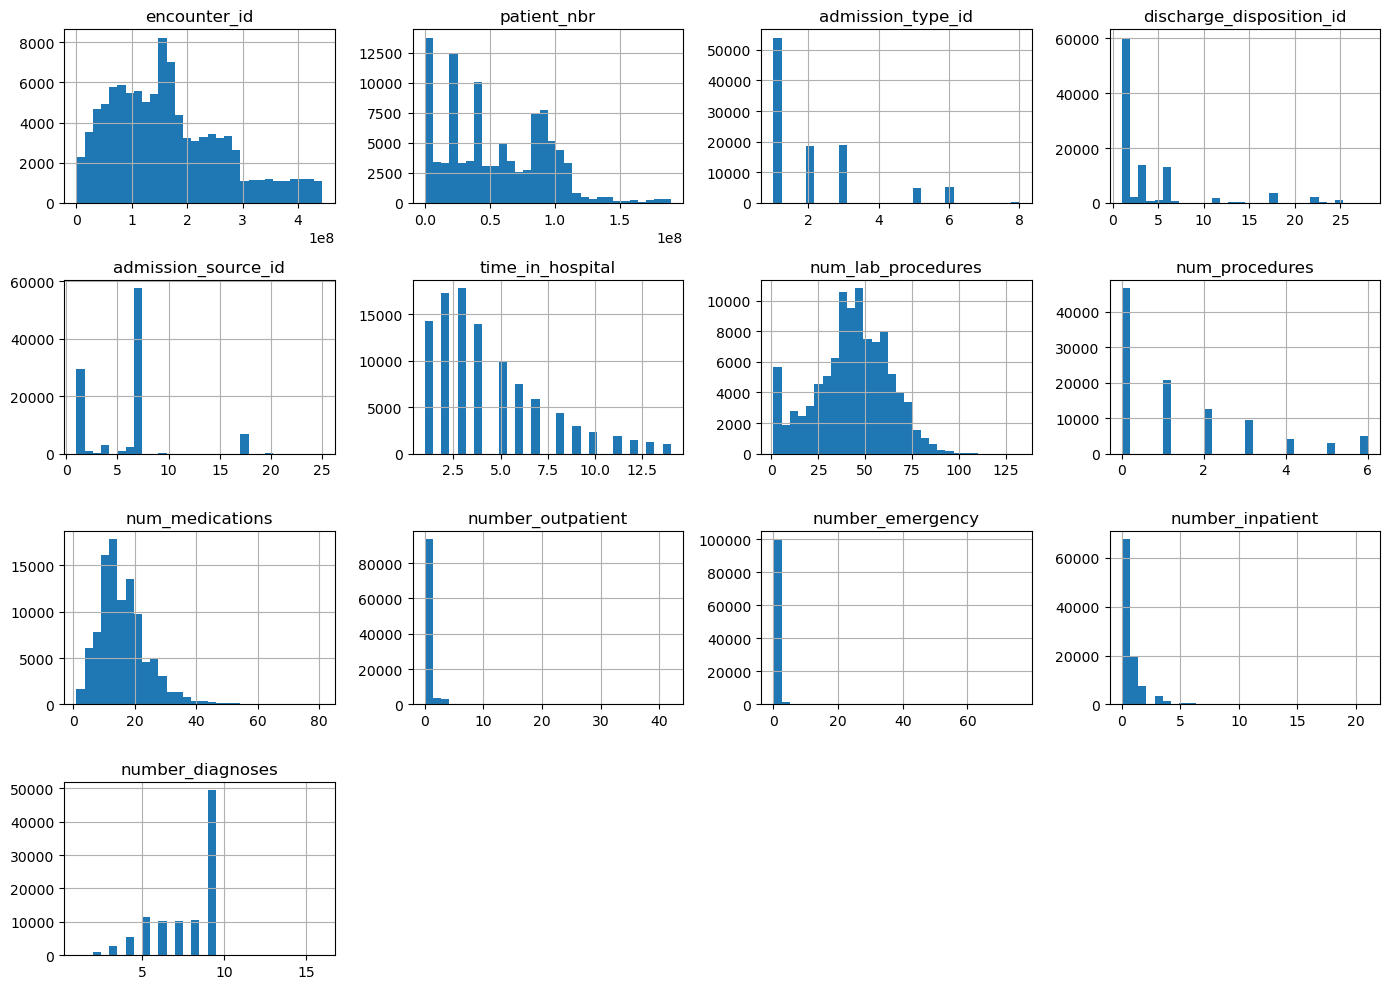

In [20]:
num_cols = df.select_dtypes("number").columns.drop("readmit_30")
df[num_cols].hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.savefig(FIG_DIR / "numeric_distributions.png", bbox_inches="tight")
plt.show()

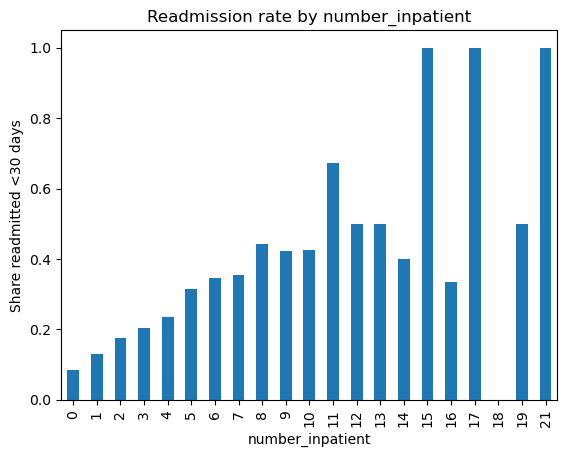

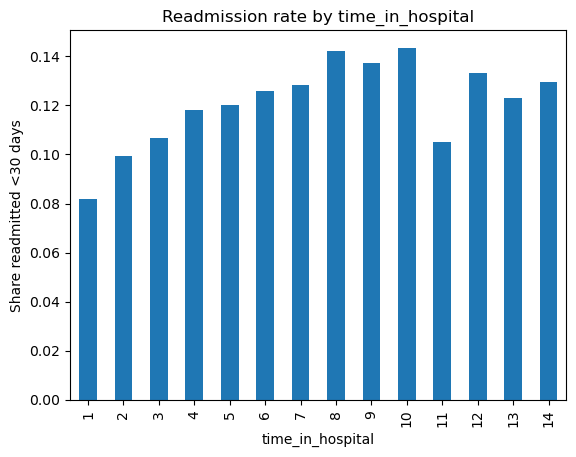

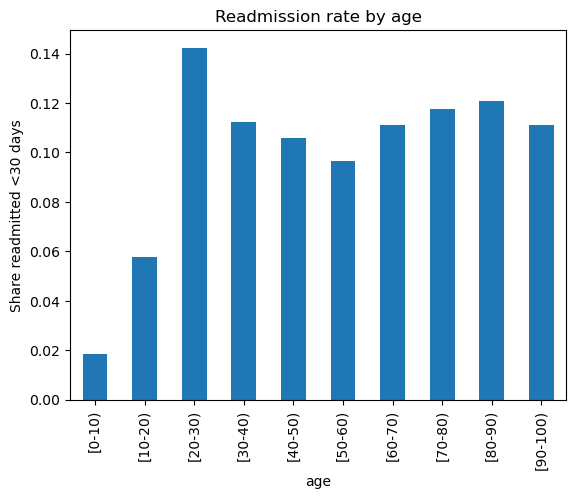

In [21]:
for col in ["number_inpatient", "time_in_hospital", "age"]:
    if col in df.columns:
        df.groupby(col, observed=True)["readmit_30"].mean().plot(kind="bar", title=f"Readmission rate by {col}")
        plt.ylabel("Share readmitted <30 days")
        plt.savefig(FIG_DIR / "Readmission_rate_by_{}.png".format(col), bbox_inches="tight")
        plt.show()

In [22]:
for col in ["race", "gender", "age"]:
    if col in df.columns:
        print(f"\n--- {col} ---")
        print(df.groupby(col, observed=True)["readmit_30"].agg(["count", "mean"]).round(3))


--- race ---
                 count   mean
race                         
?                 2273  0.083
AfricanAmerican  19210  0.112
Asian              641  0.101
Caucasian        76099  0.113
Hispanic          2037  0.104
Other             1506  0.096

--- gender ---
                 count   mean
gender                       
Female           54708  0.112
Male             47055  0.111
Unknown/Invalid      3  0.000

--- age ---
          count   mean
age                   
[0-10)      161  0.019
[10-20)     691  0.058
[20-30)    1657  0.142
[30-40)    3775  0.112
[40-50)    9685  0.106
[50-60)   17256  0.097
[60-70)   22483  0.111
[70-80)   26068  0.118
[80-90)   17197  0.121
[90-100)   2793  0.111


In [23]:
for col in ["encounter_id", "patient_nbr"]:
    print(col, "in data:", col in df.columns)

if "patient_nbr" in df.columns:
    visits = df["patient_nbr"].value_counts()
    print("Unique patients:", visits.size, "| rows:", len(df))
    print("Patients with >1 visit:", (visits > 1).sum())

encounter_id in data: True
patient_nbr in data: True
Unique patients: 71518 | rows: 101766
Patients with >1 visit: 16773



1. The classes are heavily imbalanced. Only 11.2% of encounters are readmitted within 30 days. A model that always predicts "no" gets 89% accuracy and is useless. Use PR-AUC, recall and F1, and use class weights or threshold tuning.

2. The same patients appear many times. There are 101,766 encounters but only 71,518 patients. 46% of encounters belong to patients who appear more than once, and one patient has 40 encounters. A random train/test split will leak the same patient into both sets. Split by patient_nbr, for example with GroupShuffleSplit. A patient's first visit also has a lower rate (8.8%) than the average.

3. Prior inpatient visits are the strongest single predictor. The 30-day rate climbs steadily with number_inpatient: 8.4% with none, 12.9% with 1, 17.4% with 2, 20.3% with 3, and 36.4% with 5 or more. It has the highest correlation of any numeric feature (r = 0.165). Prior emergency visits follow the same pattern, from 10.5% with none to about 30% with 4 or more.

4. Discharge destination matters a lot. Patients sent to a rehab facility (id 22) are readmitted at 27.7%, and those sent to another inpatient facility (id 5) at 20.9%. Patients sent home (id 1) are at 9.3%. Treat this column as categorical. It is stored as a number, but the codes have no order.

5. Some rows can never be readmitted. 1,642 encounters ended in death (discharge_disposition_id = 11), and their readmission rate is 0%. Hospice discharges (ids 13 and 14) are also very low, around 5–6%. These rows should be removed, because they can't be readmitted and they distort what the model learns.

6. Three columns are mostly missing. weight is 97% missing, medical_specialty 49% and payer_code 40%. Missing values are written as "?", not as NaN, which is why df.info() shows no nulls. weight should be dropped. For the other two, "missing" can be its own category.

7. Blood sugar tests are rarely done. A1C was measured in only 17% of encounters and serum glucose in 5%. Where glucose was measured, a result above 300 goes with a 14.3% readmission rate. Whether a test was ordered at all is probably more useful than the result itself.

8. Insulin changes signal higher risk. When insulin was adjusted, the rate is 13.9% for a dose decrease and 13.0% for an increase. It is 11.1% for a steady dose and 10.0% with no insulin. Any medication change raises the rate from 10.6% to 11.8%.

9. Many medication columns are almost empty. 7 of the 23 drug columns are essentially never used, including examide, citoglipton and troglitazone. More than 15 are used in less than 1% of encounters. Drop them or group them, for example into a count of medications changed.

10. Demographics barely matter, but the type of care does. Gender (11.2% vs 11.1%) and race (10–11%) make almost no difference. The age pattern is surprising: ages 20–30 have the highest rate (14.2%), higher than people over 80. Oncology and hematology patients are readmitted at about 19%, and kidney specialists' patients at 15%. Longer stays carry more risk: 9.1% for 1–2 days versus 13.4% for 8–14 days. Main diagnosis matters less than you might expect; diabetes as the main diagnosis is the highest at 13.0%.